# Rolling Correlation

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots the correlation between two assets computed over a moving window. Diversification depends on correlation, and correlation is not constant: it shifts with inflation and policy regimes and tends to rise in crises, exactly when diversification is needed most.

## When to use

- Check whether a diversifier (bonds, gold, alternatives) still diversifies
- Show regime changes in the relationship between two markets
- Stress-test assumptions in a portfolio model that uses a single correlation number

## Avoid when

- Comparing more than three or four pairs on one chart (use small multiples or a heatmap per period)
- Windows so short that the line is pure noise (under ~40 observations)

## Alternatives

- Correlation heatmap for two or three sub-periods
- Scatter of the two return series, colored by period

## Design tips

- Mark the zero line and the full-period correlation as references
- State the window length (e.g. 63 trading days ≈ 3 months)
- Correlate returns, never price levels (trending prices correlate spuriously)

## Example

Simulated daily returns for equities, government bonds and gold, 2015–2024. The stock-bond correlation flips from negative to positive in 2022, as it did when inflation returned. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(5)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
# Time-varying correlation with equities: bonds -0.35 until 2021, then +0.45 from 2022; gold drifts around +0.05.
rho_bond = np.where(dates < "2022-01-01", -0.35, 0.45) + 0.15 * np.sin(np.arange(n) / 90)
rho_gold = 0.05 + 0.2 * np.sin(np.arange(n) / 260 + 1)
z_eq, z_b, z_g = rng.standard_normal((3, n))
eq = 0.010 * z_eq
bonds = 0.004 * (rho_bond * z_eq + np.sqrt(1 - rho_bond**2) * z_b)
gold = 0.009 * (rho_gold * z_eq + np.sqrt(1 - rho_gold**2) * z_g)
rets = pd.DataFrame({"Equities": eq, "Gov. bonds": bonds, "Gold": gold}, index=dates)
window = 63
rets.head()

,Equities,Gov. bonds,Gold
2015-01-01,-0.008019,0.000368,-0.013000
2015-01-02,-0.013244,-0.001065,0.019893
2015-01-05,-0.002484,-0.001286,0.002272
2015-01-06,0.004204,-0.004452,-0.017256
2015-01-07,0.011360,0.001109,0.012376


### Plot

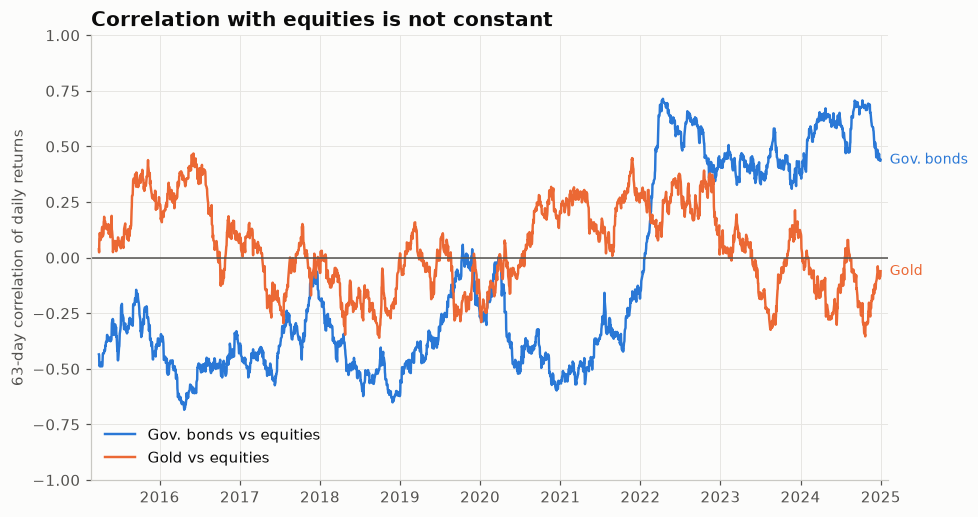

In [3]:
base = rets.columns[0]
fig, ax = plt.subplots(figsize=(9, 4.8))
for i, col in enumerate(rets.columns[1:]):
    rc = rets[base].rolling(window).corr(rets[col])
    ax.plot(rc.index, rc, color=PALETTE[i], linewidth=1.6, label=f"{col} vs {base.lower()}")
    ax.annotate(col, (rc.index[-1], rc.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=PALETTE[i])
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_ylim(-1, 1)
ax.set_ylabel(f"{window}-day correlation of daily returns")
ax.set_title(f"Correlation with {base.lower()} is not constant")
ax.legend(loc="lower left")
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

## How to read it

Each line is the 63-day correlation of an asset's returns with equity returns. Below zero, the asset tended to rise when stocks fell (a hedge). The bond line crossing above zero in 2022 means bonds and stocks fell together.

---
Standalone script: [`rolling_correlation.py`](rolling_correlation.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)